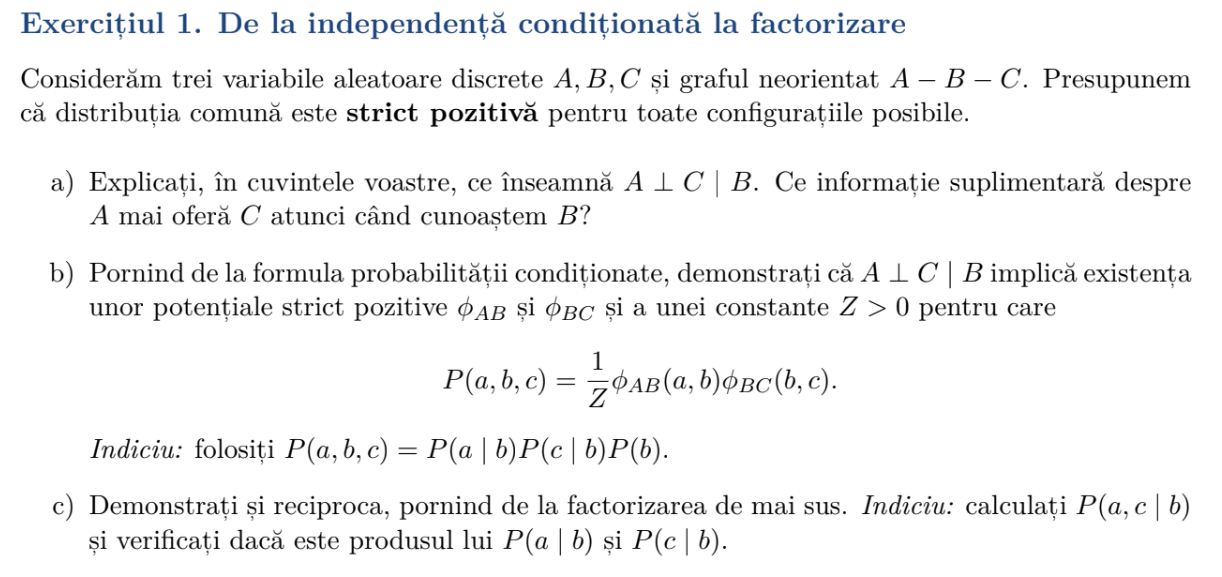

In [ ]:
#a
# inseamna ca A si C sunt independente conditionat de B.
# daca il cunoastem pe B, C nu ofera nicio informatie despre A

#b
# P(a,b,c) = P(a|b,c) * P(b,c)
# A ⊥ C | B => P(a|b,c) = P(a|b)
# => P(a,b,c) = P(a|b) * P(b,c)
# P(b,c) = P(c|b) * P(b)
# => P(a,b,c) = P(a|b) * P(c|b) * P(b) (retea bayesiana)
# fie Z = 1
# fie pAB(a,b) = P(a|b) * P(b)
# fie pBC(b,c) = P(c|b)
# => P(a,b,c) = P(a|b) * P(c|b) * P(b)

#c
# P(a,c|b) = P(a,b,c) / P(b)
# P(a,b,c) = (1/Z) * pAB(a,b) * pBC(b,c)
# P(b) = sum_a sum_c P(a,b,c) = (1/Z) * (sum_a pAB(a,b)) * (sum_c pBC(b,c))
# P(a,c|b) = pAB(a,b) / (sum_a pAB(a,b))  *   pBC(b,c) / (sum_c pBC(b,c))
# => P(a,c|b) = P(a|b) * P(c|b)

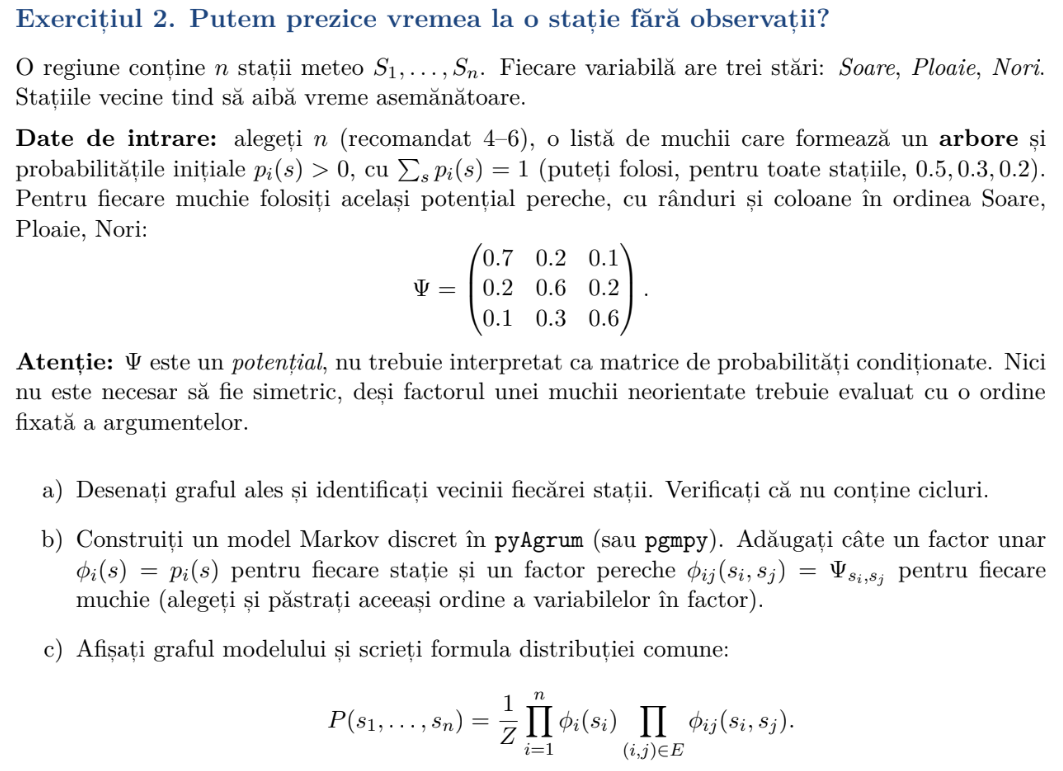 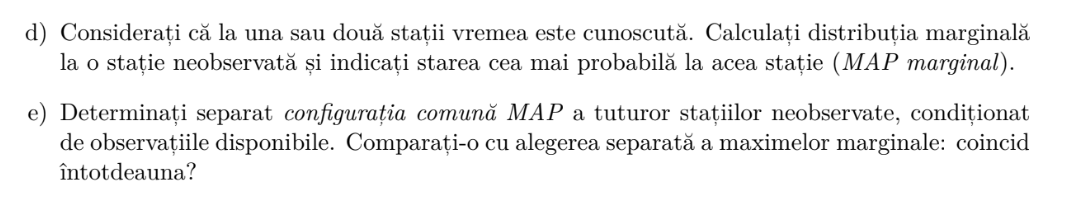

In [6]:
from pgmpy.models import DiscreteMarkovNetwork
from pgmpy.factors.discrete import DiscreteFactor
from pgmpy.inference import VariableElimination

model = DiscreteMarkovNetwork()
model.add_edges_from([('S1', 'S2'), ('S2', 'S3'), ('S3', 'S4')])

prob_initiale = [0.5, 0.3, 0.2]
phi_1 = DiscreteFactor(['S1'], cardinality=[3], values=prob_initiale)
phi_2 = DiscreteFactor(['S2'], cardinality=[3], values=prob_initiale)
phi_3 = DiscreteFactor(['S3'], cardinality=[3], values=prob_initiale)
phi_4 = DiscreteFactor(['S4'], cardinality=[3], values=prob_initiale)

psi_values = [
    0.7, 0.2, 0.1,
    0.2, 0.6, 0.2,
    0.1, 0.3, 0.6
]

phi_12 = DiscreteFactor(['S1', 'S2'], cardinality=[3, 3], values=psi_values)
phi_23 = DiscreteFactor(['S2', 'S3'], cardinality=[3, 3], values=psi_values)
phi_34 = DiscreteFactor(['S3', 'S4'], cardinality=[3, 3], values=psi_values)

model.add_factors(phi_1, phi_2, phi_3, phi_4, phi_12, phi_23, phi_34)
assert model.check_model()

In [8]:
infer = VariableElimination(model)

dist_S3 = infer.query(variables=['S3'], evidence={'S1': 0})
print(dist_S3)

marginal_map_s3 = dist_S3.values.argmax()
stari = {0: 'Soare', 1: 'Ploaie', 2: 'Nori'}
print(f"MAP marginal: {stari[marginal_map_s3]}")

+-------+-----------+
| S3    |   phi(S3) |
+=======+===========+
| S3(0) |    0.0278 |
+-------+-----------+
| S3(1) |    0.0054 |
+-------+-----------+
| S3(2) |    0.0015 |
+-------+-----------+
MAP marginal: Soare


In [9]:
joint_map = infer.map_query(variables=['S2', 'S3', 'S4'], evidence={'S1': 0})

print(joint_map)

0it [00:00, ?it/s]

{'S2': 0, 'S3': 0, 'S4': 0}


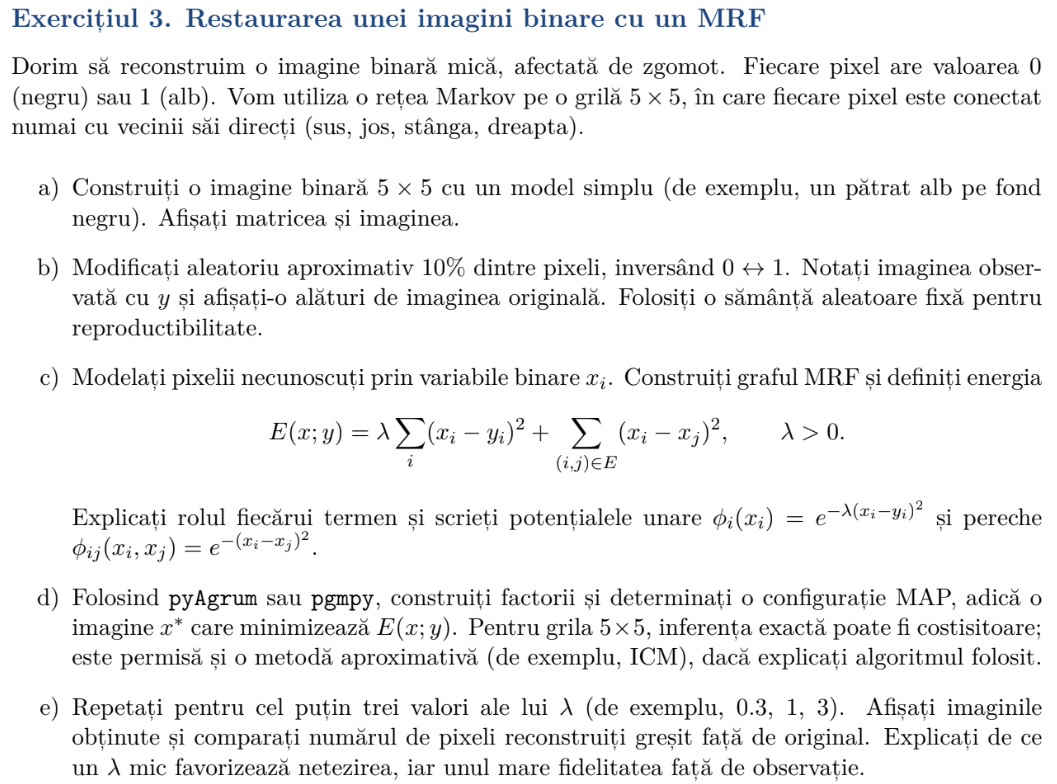

Matricea Originala:
 [[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]
Matricea Observata:
 [[0 0 0 0 0]
 [0 0 1 1 0]
 [1 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


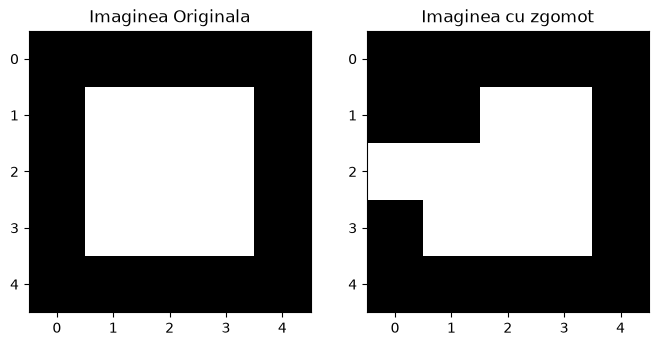

In [11]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

x_original = np.zeros((5, 5), dtype=int)
x_original[1:4, 1:4] = 1

zgomot_mask = np.random.rand(5, 5) < 0.1
y_observat = x_original.copy()
y_observat[zgomot_mask] = 1 - y_observat[zgomot_mask]
print("Matricea Originala:\n", x_original)
print("Matricea Observata:\n", y_observat)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(x_original, cmap='gray')
axes[0].set_title("Imaginea Originala")
axes[1].imshow(y_observat, cmap='gray')
axes[1].set_title("Imaginea cu zgomot")
plt.show()

<>:90: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:90: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\Brebiii\AppData\Local\Temp\ipykernel_2440\18521420.py:90: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  axes[idx+2].set_title(f"Reconstruit $\lambda={l}$\nErori: {erori}")


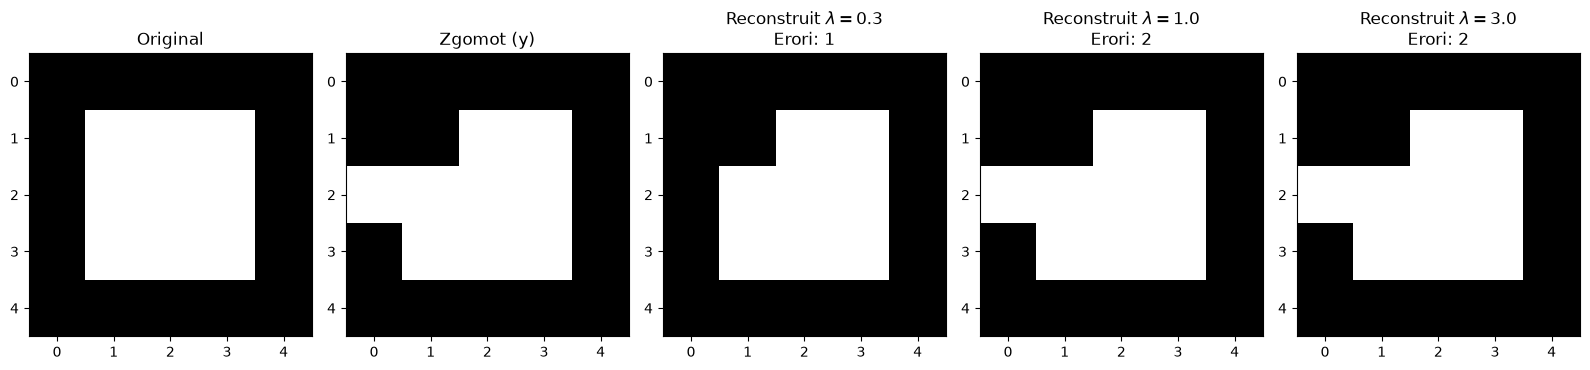

In [12]:
from pgmpy.models import MarkovNetwork
from pgmpy.factors.discrete import DiscreteFactor
import math

def construieste_factori_pgmpy(y_obs, lambda_val):
    model = MarkovNetwork()
    factors = []
    
    for i in range(5):
        for j in range(5):
            var = f"x_{i}_{j}"
            y_val = y_obs[i, j]

            val_0 = math.exp(-lambda_val * (0 - y_val)**2)
            val_1 = math.exp(-lambda_val * (1 - y_val)**2)
            f_unar = DiscreteFactor([var], cardinality=[2], values=[val_0, val_1])
            factors.append(f_unar)

            if j < 4:
                var_dr = f"x_{i}_{j+1}"
                model.add_edge(var, var_dr)
                e_diff = math.exp(-1)
                f_pereche_dr = DiscreteFactor([var, var_dr], cardinality=[2, 2], 
                                              values=[1, e_diff, e_diff, 1])
                factors.append(f_pereche_dr)

            if i < 4:
                var_jos = f"x_{i+1}_{j}"
                model.add_edge(var, var_jos)
                e_diff = math.exp(-1)
                f_pereche_jos = DiscreteFactor([var, var_jos], cardinality=[2, 2], 
                                               values=[1, e_diff, e_diff, 1])
                factors.append(f_pereche_jos)

    model.add_factors(*factors)
    return model

def icm_restaurare(y_obs, lambda_val, max_iter=10):

    x_reconstruit = y_obs.copy()
    rows, cols = x_reconstruit.shape
    
    for iteratie in range(max_iter):
        schimbari = 0
        for i in range(rows):
            for j in range(cols):
                energie_curenta = 0
                energie_noua = 0
                val_curenta = x_reconstruit[i, j]
                val_opusa = 1 - val_curenta

                e_data_curenta = lambda_val * (val_curenta - y_obs[i, j])**2
                e_data_noua = lambda_val * (val_opusa - y_obs[i, j])**2

                e_netezire_curenta = 0
                e_netezire_noua = 0

                vecini = [(i-1, j), (i+1, j), (i, j-1), (i, j+1)]
                for vi, vj in vecini:
                    if 0 <= vi < rows and 0 <= vj < cols:
                        v_val = x_reconstruit[vi, vj]
                        e_netezire_curenta += (val_curenta - v_val)**2
                        e_netezire_noua += (val_opusa - v_val)**2

                e_tot_curenta = e_data_curenta + e_netezire_curenta
                e_tot_noua = e_data_noua + e_netezire_noua

                if e_tot_noua < e_tot_curenta:
                    x_reconstruit[i, j] = val_opusa
                    schimbari += 1

        if schimbari == 0:
            break
            
    return x_reconstruit

valori_lambda = [0.3, 1.0, 3.0]
fig, axes = plt.subplots(1, len(valori_lambda) + 2, figsize=(16, 4))

axes[0].imshow(x_original, cmap='gray')
axes[0].set_title("Original")
axes[1].imshow(y_observat, cmap='gray')
axes[1].set_title("Zgomot (y)")

for idx, l in enumerate(valori_lambda):
    x_map = icm_restaurare(y_observat, l)
    erori = np.sum(x_map != x_original)
    
    axes[idx+2].imshow(x_map, cmap='gray')
    axes[idx+2].set_title(f"Reconstruit $\lambda={l}$\nErori: {erori}")

plt.tight_layout()
plt.show()